# The repo’s Dataset class wants a CSV with columns index,mid,display_name.

In [36]:
import csv

classes = [
    "DogBark",
    "Footstep",
    "GunShot",
    "Keyboard",
    "MovingMotorVehicle",
    "Rain",
    "Sneeze"  
]

mids = [
    "/m/dog_bark",
    "/m/footstep",
    "/m/gun_shot",
    "/m/keyboard",
    "/m/moving_motor_vehicle",
    "/m/rain",
    "/m/sneeze_cough"
]

with open("E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/class_labels_indices.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["index", "mid", "display_name"])
    for i, (m, c) in enumerate(zip(mids, classes)):
        w.writerow([i, m, c])

# Build JSON metadata files (train_data.json, test_data.json)

# Correct the Dev.csv and Eval.csv

In [29]:
import pandas as pd
import os
import pathlib
import json

# Define directories
root = pathlib.Path("E:/media_project")
dev_dir = root / "DCASE_2023_Challenge_Task_7_Dataset/dev"
eval_dir = root / "DCASE_2023_Challenge_Task_7_Dataset/eval"

# Class mapping for directory names to category names
dir_to_category = {
    "dog_bark": "DogBark",
    "footstep": "Footstep",
    "gunshot": "GunShot",
    "keyboard": "Keyboard",
    "moving_motor_vehicle": "MovingMotorVehicle",
    "rain": "Rain",
    "sneeze_cough": "Sneeze"
}

# Function to collect valid .wav files and create CSV
def create_metadata_csv(input_dir, output_csv):
    data = {"current_file_path": [], "category": []}
    for class_dir in dir_to_category.keys():
        class_path = input_dir / class_dir
        if class_path.exists():
            for file in class_path.glob("*.wav"):
                # Create relative path starting with DCASE_...
                rel_path = str(file.relative_to(root)).replace("\\", "/")
                data["current_file_path"].append(rel_path)
                data["category"].append(dir_to_category[class_dir])
        else:
            print(f"Directory not found: {class_path}")
    df = pd.DataFrame(data)
    df.to_csv(output_csv, index=False)
    print(f"Saved {len(df)} samples to {output_csv}")
    return df

# Function to convert CSV to JSONL
def convert_to_jsonl(meta_csv, out_jsonl):
    df = pd.read_csv(meta_csv)
    label_map = {
        "DogBark": "/m/dog_bark",
        "Footstep": "/m/footstep",
        "GunShot": "/m/gun_shot",
        "Keyboard": "/m/keyboard",
        "MovingMotorVehicle": "/m/moving_motor_vehicle",
        "Rain": "/m/rain",
        "Sneeze": "/m/sneeze_cough"
    }
    with open(out_jsonl, "w", encoding="utf-8") as f:
        for _, row in df.iterrows():
            abs_path = str((root / row["current_file_path"]).resolve())
            if os.path.exists(abs_path):
                line = {"wav": abs_path, "labels": label_map[row["category"]]}
                f.write(json.dumps(line) + "\n")
    print(f"Saved JSONL to {out_jsonl}")

# Update DevMeta.csv
dev_csv = "E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/DevMeta.csv"
create_metadata_csv(dev_dir, dev_csv)

# Update EvalMeta.csv
eval_csv = "E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/EvalMeta.csv"
create_metadata_csv(eval_dir, eval_csv)

# Regenerate train_data.json and test_data.json
convert_to_jsonl(dev_csv, "E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/train_data.json")
convert_to_jsonl(eval_csv, "E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/test_data.json")

Saved 4850 samples to E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/DevMeta.csv
Saved 700 samples to E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/EvalMeta.csv
Saved JSONL to E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/train_data.json
Saved JSONL to E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/test_data.json


# Verify dataset loading

In [40]:
import sys
import os
sys.path.append(os.path.abspath("E:/media_project/Dcase2023_task7/src"))
from utilities.data.dataset import Dataset
import yaml
cfg = yaml.safe_load(open("configs/small.yaml"))
ds = Dataset(
    preprocess_config=cfg["preprocess_config"],
    train_config=cfg["train_config"],
    train=True
)
print("Samples:", len(ds))
print("One sample shapes:", [x.shape if hasattr(x,"shape") else type(x) for x in ds[0]])

Data size: 4850
Use mixup rate of 0.0; Use SpecAug (T,F) of (0, 0); Use blurring effect or not False
number of classes is 7
Samples: 4850
One sample shapes: [torch.Size([172, 128]), torch.Size([172, 512]), torch.Size([7]), <class 'str'>, torch.Size([88064]), <class 'str'>]


Data size: 4850
Use mixup rate of 0.0; Use SpecAug (T,F) of (0, 0); Use blurring effect or not False
number of classes is 7
Dataset size: 4850
Number of classes: 7
Mixup rate: 0.0
SpecAug (freqm, timem): (0, 0)
Blurring effect: False
Sampling rate: 22050
Mel-spectrogram shape: torch.Size([172, 128])
Found 4850 valid samples out of 4850
Selected random sample index: 451

Class 0 (DogBark) - Sample Index: 451
Metadata 1: E:\media_project\DCASE_2023_Challenge_Task_7_Dataset\dev\dog_bark\452.wav
Metadata 2: DogBark.


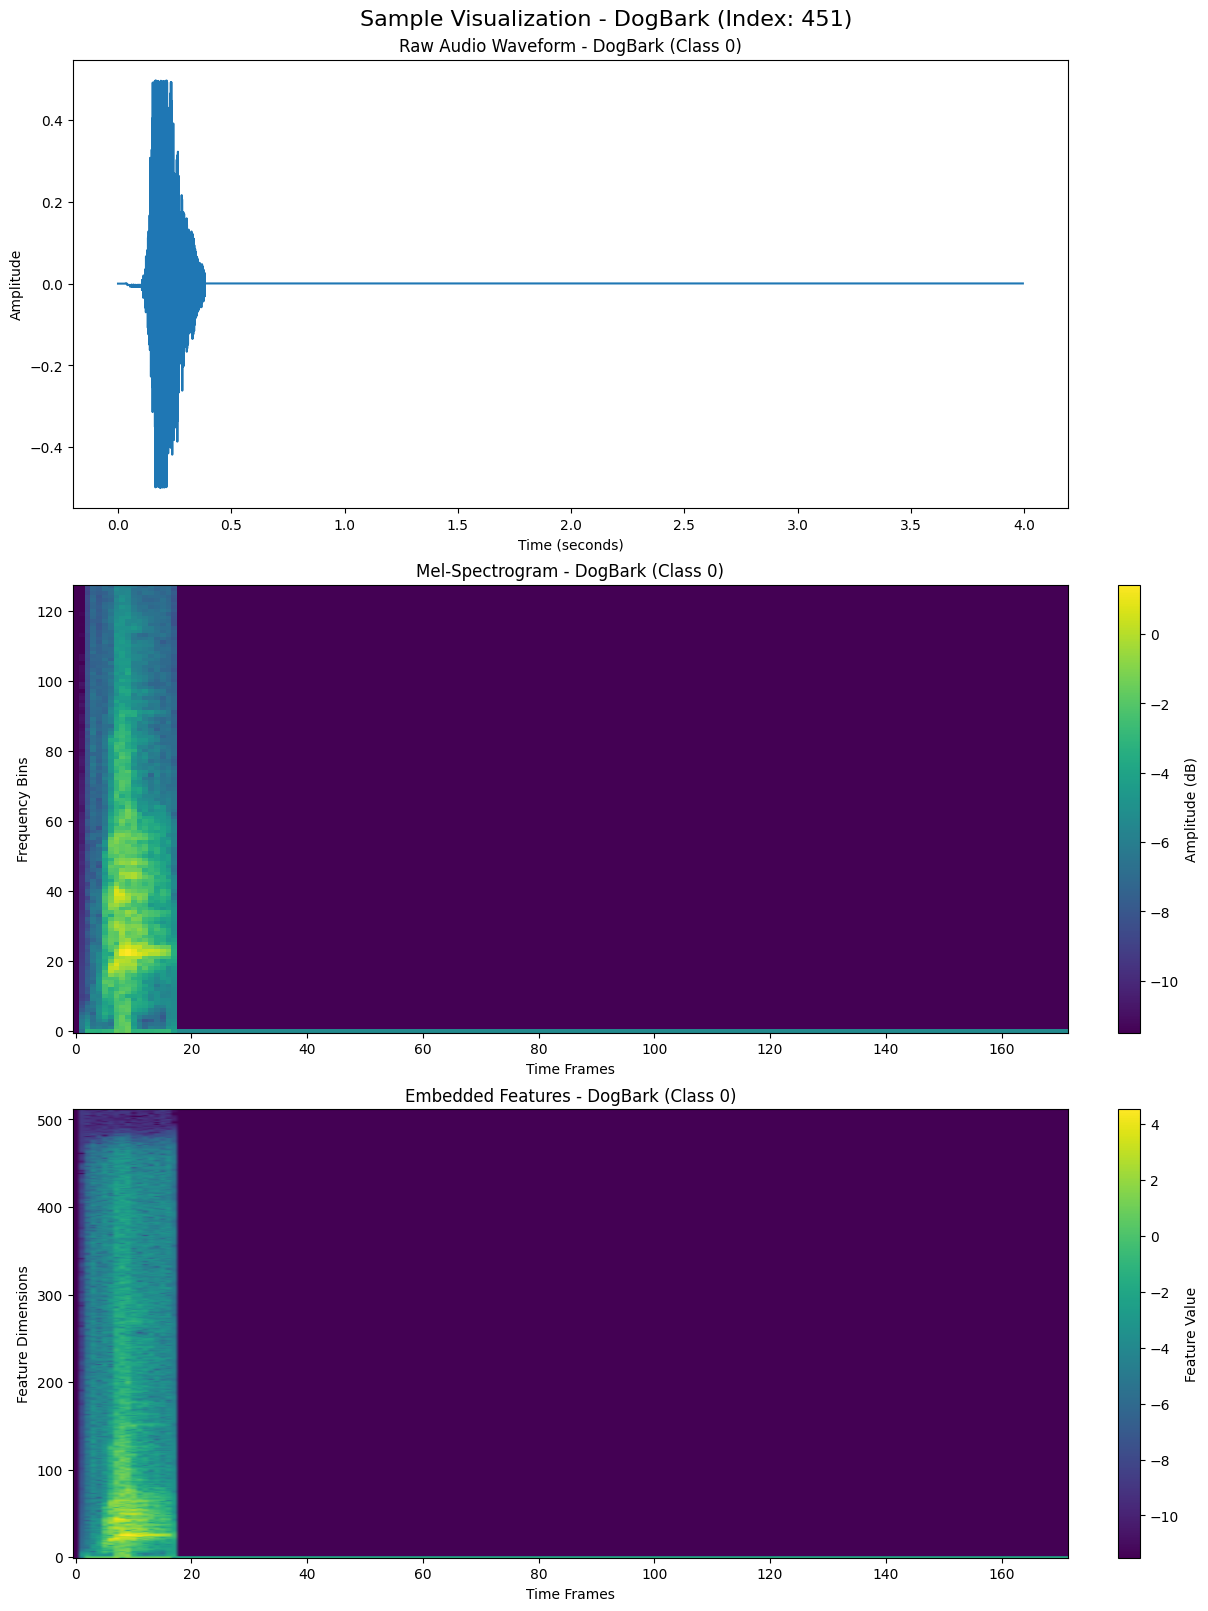

In [39]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import os
import sys
import yaml
import json
from pathlib import Path

# Add project path
sys.path.append(os.path.abspath("E:/media_project/Dcase2023_task7/src"))
from utilities.data.dataset import Dataset

# Load configuration
cfg = yaml.safe_load(open("configs/small.yaml"))

# Class ID to name mapping
class_names = [
    "DogBark", "Footstep", "GunShot", "Keyboard", 
    "MovingMotorVehicle", "Rain", "Sneeze"
]

# Initialize dataset
train_data_path = "E:/media_project/DCASE_2023_Challenge_Task_7_Dataset/train_data.json"
cfg["preprocess_config"]["path"]["train_data"] = train_data_path
ds = Dataset(
    preprocess_config=cfg["preprocess_config"],
    train_config=cfg["train_config"],
    train=True
)

# Dataset parameters
print(f"Dataset size: {len(ds)}")
print(f"Number of classes: {len(class_names)}")
print(f"Mixup rate: {cfg.get('preprocess_config', {}).get('mixup', 0.0)}")
print(f"SpecAug (freqm, timem): ({cfg.get('preprocess_config', {}).get('freqm', 0)}, {cfg.get('preprocess_config', {}).get('timem', 0)})")
print(f"Blurring effect: {cfg.get('preprocess_config', {}).get('blur', False)}")
print(f"Sampling rate: {cfg.get('preprocess_config', {}).get('sampling_rate', 22050)}")
print(f"Mel-spectrogram shape: {ds[0][0].shape if hasattr(ds[0][0], 'shape') else 'Unknown'}")

# Find valid samples
num_samples = len(ds)
valid_indices = []
for i in range(num_samples):
    try:
        sample = ds[i]
        file_path = sample[3]  # Metadata 1 (file path)
        # Handle ./ prefix if present
        file_path = file_path.replace("./", "")
        if os.path.exists(file_path):
            valid_indices.append(i)
        else:
            print(f"Invalid file path at index {i}: {file_path}")
    except Exception as e:
        print(f"Error at index {i}: {e}")
        continue
print(f"Found {len(valid_indices)} valid samples out of {num_samples}")

# Pick a random valid sample
if not valid_indices:
    raise Exception("No valid samples found in dataset")
random_idx = random.choice(valid_indices)
print(f"Selected random sample index: {random_idx}")

# Load sample
sample = ds[random_idx]
spec1 = sample[0].numpy()  # (344, 128) - mel-spectrogram
spec2 = sample[1].numpy()  # (344, 512) - embedded features
label = sample[2].numpy()  # (7) - label vector
metadata1 = sample[3]      # file path
waveform = sample[4].numpy()  # (88200) - raw audio
metadata2 = sample[5]      # additional metadata

# Get class info
class_id = np.argmax(label)
class_name = class_names[class_id]

# Print metadata
print(f"\nClass {class_id} ({class_name}) - Sample Index: {random_idx}")
print("Metadata 1:", metadata1)
print("Metadata 2:", metadata2)

# Create figure with subplots
fig, axs = plt.subplots(3, 1, figsize=(12, 16), constrained_layout=True)
fig.suptitle(f'Sample Visualization - {class_name} (Index: {random_idx})', fontsize=16)

# Plot 1: Waveform
sampling_rate = cfg.get('preprocess_config', {}).get('sampling_rate', 22050)
time_axis = np.arange(len(waveform)) / sampling_rate
axs[0].plot(time_axis, waveform)
axs[0].set_title(f'Raw Audio Waveform - {class_name} (Class {class_id})')
axs[0].set_xlabel('Time (seconds)')
axs[0].set_ylabel('Amplitude')

# Plot 2: Mel-Spectrogram
im1 = axs[1].imshow(spec1.T, origin='lower', aspect='auto', cmap='viridis')
axs[1].set_title(f'Mel-Spectrogram - {class_name} (Class {class_id})')
axs[1].set_xlabel('Time Frames')
axs[1].set_ylabel('Frequency Bins')
fig.colorbar(im1, ax=axs[1], label='Amplitude (dB)')

# Plot 3: Embedded Features
im2 = axs[2].imshow(spec2.T, origin='lower', aspect='auto', cmap='viridis')
axs[2].set_title(f'Embedded Features - {class_name} (Class {class_id})')
axs[2].set_xlabel('Time Frames')
axs[2].set_ylabel('Feature Dimensions')
fig.colorbar(im2, ax=axs[2], label='Feature Value')

# show plot
plt.show()

JSON Files

In [1]:
import csv, json, os

root = "/home/mukh1485/dcase_dataset"

def make_json(csv_path, audio_root, out_json):
    with open(csv_path, newline="", encoding="utf-8") as f:
        r = csv.DictReader(f)
        rows = []
        for row in r:
            fn = row.get("current_file_path")
            lab = row.get("category")
            if not fn:
                raise RuntimeError("Could not find 'current_file_path' column in CSV.")
            if not lab:
                lab = os.path.basename(os.path.dirname(fn)) or "Unknown"
            # Strip the 'DCASE_2023_Challenge_Task_7_Dataset/dev' or 'DCASE_2023_Challenge_Task_7_Dataset/eval' prefix
            fn = fn.replace("DCASE_2023_Challenge_Task_7_Dataset/dev/", "").replace("DCASE_2023_Challenge_Task_7_Dataset/eval/", "")
            wav = fn if os.path.isabs(fn) else os.path.join(audio_root, fn)
            rows.append({"wav": wav, "text": lab})
    with open(out_json, "w", encoding="utf-8") as g:
        json.dump(rows, g, indent=2)
    print(f"Wrote {out_json} with {len(rows)} items")

make_json(os.path.join(root, "DevMeta.csv"),
          os.path.join(root, "dev"),
          "/home/mukh1485/media_project_update2/metadata/train_data.json")

make_json(os.path.join(root, "EvalMeta.csv"),
          os.path.join(root, "eval"),
          "/home/mukh1485/media_project_update2/metadata/test_data.json")

Wrote /home/mukh1485/media_project_update2/metadata/train_data.json with 4850 items
Wrote /home/mukh1485/media_project_update2/metadata/test_data.json with 700 items


In [2]:
#!/usr/bin/env python3
import os, re, json, shutil

# === set these to your actual files ===
train_json = "/home/mukh1485/media_project_update2/metadata/train_data.json"
test_json  = "/home/mukh1485/media_project_update2/metadata/test_data.json"

# If we need to search, we’ll index under this root:
dataset_root = "/home/mukh1485/dcase_dataset"

# ---------- normalization helpers ----------
def norm_class(s: str) -> str:
    s = s.strip().lower()
    s = s.replace("-", "_").replace(" ", "_").replace("\\", "/")
    s = re.sub(r'(?i)dog[ _]?bark', 'dog_bark', s)
    s = re.sub(r'(?i)foot[ _]?step', 'footstep', s)
    s = re.sub(r'(?i)gun[ _]?shot', 'gun_shot', s)
    s = re.sub(r'(?i)moving[ _]?motor[ _]?vehicle', 'moving_motor_vehicle', s)
    s = re.sub(r'(?i)sneeze[ _]?/?cough', 'sneeze_cough', s)
    return s

def zero3(stem: str) -> str:
    # if the filename stem is a small integer, pad to 3 digits
    if re.fullmatch(r'\d{1,3}', stem):
        return f"{int(stem):03d}"
    return stem

def fix_path(p: str) -> str:
    q = p
    # collapse accidental nested dataset pieces
    q = q.replace("/DCASE_2023_Challenge_Task_7_Dataset/dev/", "/dev/")
    q = q.replace("/DCASE_2023_Challenge_Task_7_Dataset/eval/", "/eval/")
    # normalize class segments
    q = re.sub(r'(?i)/dog[ _]?bark/', '/dog_bark/', q)
    q = re.sub(r'(?i)/foot[ _]?step/', '/footstep/', q)
    q = re.sub(r'(?i)/gun[ _]?shot/', '/gun_shot/', q)
    q = re.sub(r'(?i)/moving[ _]?motor[ _]?vehicle/', '/moving_motor_vehicle/', q)
    q = re.sub(r'(?i)/sneeze[ _]?/?cough/', '/sneeze_cough/', q)
    # zero-pad trailing number
    m = re.search(r'/(\d{1,3})\.wav$', q)
    if m:
        n = int(m.group(1))
        q = q[:m.start(1)] + f"{n:03d}" + q[m.end(1):]
    return q

# ---------- build an index of real files under dataset_root ----------
def build_index(root: str):
    idx = {}  # keys: (class_norm, stem) -> full_path
    for dirpath, _, files in os.walk(root):
        for fn in files:
            if not fn.lower().endswith(".wav"):
                continue
            full = os.path.join(dirpath, fn)
            cls = os.path.basename(os.path.dirname(full))
            cls = norm_class(cls)
            stem = os.path.splitext(fn)[0]
            keys = {(cls, stem), (cls, zero3(stem))}
            for k in keys:
                idx[k] = full
    return idx

INDEX = build_index(dataset_root)

# ---------- repair function that overwrites in place ----------
def clean_in_place(path: str):
    with open(path, "r", encoding="utf-8") as f:
        items = json.load(f)

    fixed, missing = [], []
    for rec in items:
        p = rec["wav"]
        if os.path.exists(p):
            fixed.append(rec)
            continue

        q = fix_path(p)
        if os.path.exists(q):
            rec = dict(rec); rec["wav"] = q
            fixed.append(rec)
            continue

        # last-resort: try to recover via index
        # use JSON "text" if available, else class folder name from the path
        cls_from_text = norm_class(rec.get("text", "")) if "text" in rec else ""
        if not cls_from_text:
            # extract class dir from original path if possible
            m = re.search(r'/((?:dog_bark|footstep|gun_shot|keyboard|moving_motor_vehicle|rain|sneeze_cough))/\d+\.wav$', fix_path(p))
            if m: cls_from_text = m.group(1)

        stem = os.path.splitext(os.path.basename(p))[0]
        cand = INDEX.get((cls_from_text, stem)) or INDEX.get((cls_from_text, zero3(stem)))

        if cand and os.path.exists(cand):
            rec = dict(rec); rec["wav"] = cand
            fixed.append(rec)
        else:
            missing.append(p)

    print(f"[{os.path.basename(path)}] kept={len(fixed)}  missing={len(missing)}")
    if missing:
        print("  examples of missing:", *missing[:10], sep="\n  ")

    # backup and overwrite atomically
    bak = path + ".bak"
    tmp = path + ".tmp"
    try:
        shutil.copy2(path, bak)
    except Exception:
        pass
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(fixed, f, ensure_ascii=False, indent=2)
    os.replace(tmp, path)

# ---- run on both files (overwrites them) ----
clean_in_place(train_json)
clean_in_place(test_json)
print("Done. JSONs updated in place (backups: *.bak).")


[train_data.json] kept=4850  missing=0
[test_data.json] kept=700  missing=0
Done. JSONs updated in place (backups: *.bak).


In [2]:
import json
p="/home/mukh1485/media_project_update2/metadata/train_data.json"
print("train items:", len(json.load(open(p))))

train items: 4850


In [4]:
import torch, glob
ckpt = sorted(glob.glob("/home/mukh1485/media_project_update2/model_logs/dcase7_finetune_unet_text/checkpoints/last.ckpt"))[-1]
state = torch.load(ckpt, map_location="cpu")
print("ckpt:", ckpt)
print("global_step:", state.get("global_step", "not_found"))

/usr/tmp/ipykernel_2369091/89354116.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(ckpt, map_location="cpu")


ckpt: /home/mukh1485/media_project_update2/model_logs/dcase7_finetune_unet_text/checkpoints/last.ckpt
global_step: 61250


In [10]:
import yaml, json
y="/home/mukh1485/media_project_update2/configs/dcase7_finetune.yaml"
cfg=yaml.safe_load(open(y))
p=cfg["preprocess_config"]["path"]["train_data"]
print("train_data path from YAML:", p)
print("#items:", len(json.load(open(p))))

train_data path from YAML: /home/mukh1485/media_project_update2/metadata/train_data.json
#items: 4850


In [11]:
import yaml, json, math
y="/home/mukh1485/media_project_update2/configs/dcase7_finetune.yaml"
cfg=yaml.safe_load(open(y))
p=cfg["preprocess_config"]["path"]["train_data"]
bs=cfg["model"]["params"]["batchsize"]
n=len(json.load(open(p)))
print("train_data:", p)
print("#items:", n, " batch_size:", bs)
print("steps_per_epoch:", math.ceil(n/bs))

train_data: /home/mukh1485/media_project_update2/metadata/train_data.json
#items: 4850  batch_size: 4
steps_per_epoch: 1213


In [12]:
import torch, glob, yaml, json, math
ckpt=sorted(glob.glob("/home/mukh1485/media_project_update2/model_logs/dcase7_finetune_unet_text/checkpoints/last.ckpt"))[-1]
state=torch.load(ckpt, map_location="cpu")
S=state.get("global_step",0)
Y="/home/mukh1485/media_project_update2/configs/dcase7_finetune.yaml"
cfg=yaml.safe_load(open(Y))
p=cfg["preprocess_config"]["path"]["train_data"]
bs=cfg["model"]["params"]["batchsize"]
n=len(json.load(open(p)))
spe=math.ceil(n/bs)
steps_left=max(0,80000-S)
print("global_step:",S,"  steps/epoch:",spe,"  steps_left:",steps_left)
print("epochs_left:", math.ceil(steps_left/spe))


/usr/tmp/ipykernel_2369091/103188693.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state=torch.load(ckpt, map_location="cpu")


global_step: 61250   steps/epoch: 1213   steps_left: 18750
epochs_left: 16
